# Drone Fleet Optimizer

Extend the original single-drone RRT* delivery simulation into a **multi-drone fleet optimization system**.

The fleet assigns deliveries to different drones while respecting payload and battery limits, then uses RRT* for obstacle-aware route planning. The objective is to complete as many deliveries as possible while minimizing travel distance.

This is the natural next step from the uploaded project: **task allocation + path planning + resource constraints**.

The implementation intentionally starts with a greedy heuristic instead of machine learning. That gives you a measurable baseline before adding more sophisticated optimization.

Could not assign delivery at (40, 90) (6kg).
Fleet assignment:
Drone-1 -> [(50, 50), (30, 30)]
Drone-2 -> [(75, 20), (20, 60), (80, 80), (15, 85)]
Drone-3 -> [(10, 10)]

--- Drone-1 ---
Delivered 5kg to (50, 50) | distance=70.71 | battery=229.29
Delivered 4kg to (30, 30) | distance=28.28 | battery=201.01
Returned to base | distance=42.43 | battery=158.58

--- Drone-2 ---
Delivered 4kg to (75, 20) | distance=77.62 | battery=182.38
Delivered 3kg to (20, 60) | distance=68.01 | battery=114.37
Delivered 2kg to (80, 80) | distance=63.25 | battery=51.13
Delivered 2kg to (15, 85) | distance=65.19 | battery=-14.07
Returned to base | distance=86.31 | battery=-100.38

--- Drone-3 ---
Delivered 3kg to (10, 10) | distance=14.14 | battery=205.86
Returned to base | distance=14.14 | battery=191.72

========== FLEET RESULTS ==========
Deliveries completed: 7/8
Total distance: 530.08 units
Drone-1: distance=141.42, battery_remaining=158.58, deliveries=2
Drone-2: distance=360.38, battery_remaining=-100.3

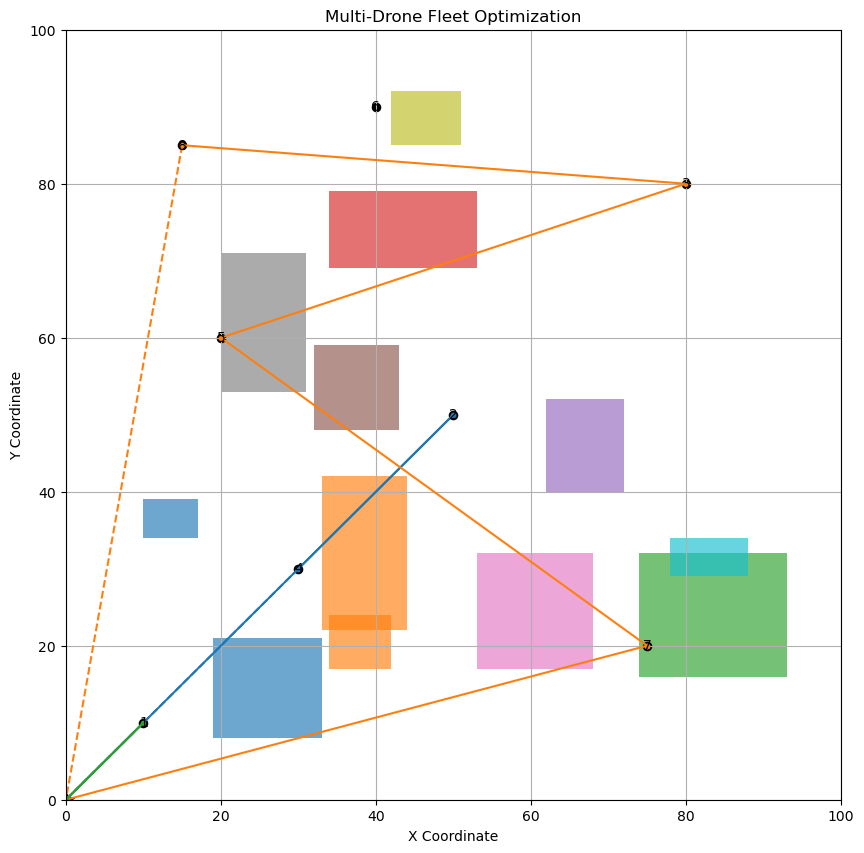

In [1]:

import math
import random
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from matplotlib.lines import Line2D

random.seed(42)
np.random.seed(42)

MAP_SIZE = (100, 100)
STEP_SIZE = 8
MAX_ITER = 500
START = (0, 0)

DELIVERY_POINTS = [
    (10, 10), (50, 50), (80, 80), (30, 30),
    (20, 60), (40, 90), (75, 20), (15, 85)
]
WEIGHTS = [3, 5, 2, 4, 3, 6, 4, 2]


@dataclass
class Drone:
    name: str
    payload_limit: float
    battery_limit: float
    position: tuple = START
    battery: float = field(init=False)
    load: float = 0
    distance_travelled: float = 0
    deliveries: list = field(default_factory=list)

    def __post_init__(self):
        self.battery = self.battery_limit

    def can_carry(self, weight):
        return self.load + weight <= self.payload_limit

    def can_fly(self, distance_required):
        return self.battery >= distance_required

    def consume(self, distance):
        self.battery -= distance
        self.distance_travelled += distance


def distance(p1, p2):
    return float(np.linalg.norm(np.array(p1) - np.array(p2)))


def check_overlap(rect1, rect2):
    (x1, y1), (x2, y2) = rect1
    (a1, b1), (a2, b2) = rect2
    return not (x2 <= a1 or a2 <= x1 or y2 <= b1 or b2 <= y1)


def generate_random_map(map_size, num_buildings=8, num_no_fly_zones=4):
    buildings, no_fly_zones = [], []

    for _ in range(num_buildings):
        for _attempt in range(1000):
            x1 = random.randint(5, map_size[0] - 25)
            y1 = random.randint(5, map_size[1] - 25)
            x2 = x1 + random.randint(10, 20)
            y2 = y1 + random.randint(10, 20)
            candidate = ((x1, y1), (x2, y2))
            if not any(check_overlap(candidate, b) for b in buildings):
                buildings.append(candidate)
                break

    for _ in range(num_no_fly_zones):
        for _attempt in range(1000):
            x1 = random.randint(5, map_size[0] - 15)
            y1 = random.randint(5, map_size[1] - 15)
            x2 = x1 + random.randint(5, 10)
            y2 = y1 + random.randint(5, 10)
            candidate = ((x1, y1), (x2, y2))
            if not any(check_overlap(candidate, z) for z in no_fly_zones):
                no_fly_zones.append(candidate)
                break

    return buildings, no_fly_zones


def point_in_zone(point, zone, buffer_distance=1):
    (x1, y1), (x2, y2) = zone
    x1 -= buffer_distance
    y1 -= buffer_distance
    x2 += buffer_distance
    y2 += buffer_distance
    return x1 <= point[0] <= x2 and y1 <= point[1] <= y2


def is_collision_free(p1, p2, no_fly_zones, samples=20):
    p1, p2 = np.array(p1, dtype=float), np.array(p2, dtype=float)
    for t in np.linspace(0, 1, samples):
        point = tuple(p1 + t * (p2 - p1))
        if any(point_in_zone(point, zone) for zone in no_fly_zones):
            return False
    return True


class RRTStar:
    def __init__(self, start, goal, no_fly_zones,
                 step_size=STEP_SIZE, max_iter=MAX_ITER, radius=15):
        self.start = start
        self.goal = goal
        self.no_fly_zones = no_fly_zones
        self.step_size = step_size
        self.max_iter = max_iter
        self.radius = radius
        self.tree = {start: None}
        self.costs = {start: 0.0}

    def nearest(self, point):
        return min(self.tree, key=lambda node: distance(node, point))

    def extend(self, random_point):
        nearest_node = self.nearest(random_point)
        direction = np.array(random_point) - np.array(nearest_node)
        length = np.linalg.norm(direction)

        if length == 0:
            return None

        step = min(self.step_size, length)
        new_node = tuple(np.array(nearest_node) + step * direction / length)

        if not (0 <= new_node[0] <= MAP_SIZE[0] and
                0 <= new_node[1] <= MAP_SIZE[1]):
            return None

        if not is_collision_free(nearest_node, new_node, self.no_fly_zones):
            return None

        self.tree[new_node] = nearest_node
        self.costs[new_node] = (
            self.costs[nearest_node] + distance(nearest_node, new_node)
        )
        self.rewire(new_node)
        return new_node

    def rewire(self, new_node):
        for node in list(self.tree.keys()):
            if node == new_node:
                continue
            edge = distance(node, new_node)
            if edge <= self.radius and is_collision_free(
                new_node, node, self.no_fly_zones
            ):
                candidate = self.costs[new_node] + edge
                if candidate < self.costs[node]:
                    self.tree[node] = new_node
                    self.costs[node] = candidate

    def find_path(self):
        if is_collision_free(self.start, self.goal, self.no_fly_zones):
            return [self.start, self.goal]

        for _ in range(self.max_iter):
            random_point = (
                random.uniform(0, MAP_SIZE[0]),
                random.uniform(0, MAP_SIZE[1])
            )
            new_node = self.extend(random_point)

            if new_node and distance(new_node, self.goal) <= self.step_size:
                if is_collision_free(new_node, self.goal, self.no_fly_zones):
                    self.tree[self.goal] = new_node
                    self.costs[self.goal] = (
                        self.costs[new_node] + distance(new_node, self.goal)
                    )
                    return self.reconstruct_path()
        return None

    def reconstruct_path(self):
        path, node = [], self.goal
        while node is not None:
            path.append(node)
            node = self.tree.get(node)
        return path[::-1]


def path_distance(path):
    if not path or len(path) < 2:
        return float("inf")
    return sum(distance(path[i], path[i + 1]) for i in range(len(path) - 1))


def plan_route(start, goal, no_fly_zones):
    return RRTStar(start, goal, no_fly_zones).find_path()


def assign_deliveries(drones, deliveries, weights, no_fly_zones):
    assignments = {drone.name: [] for drone in drones}
    remaining = sorted(zip(deliveries, weights), key=lambda x: x[1], reverse=True)

    for point, weight in remaining:
        candidates = []

        for drone in drones:
            if not drone.can_carry(weight):
                continue

            path = plan_route(drone.position, point, no_fly_zones)
            return_path = plan_route(point, START, no_fly_zones)

            if path is None or return_path is None:
                continue

            required = path_distance(path) + path_distance(return_path)

            if drone.can_fly(required):
                candidates.append((required, drone))

        if not candidates:
            print(f"Could not assign delivery at {point} ({weight}kg).")
            continue

        _, selected = min(candidates, key=lambda x: x[0])

        assignments[selected.name].append({
            "point": point,
            "weight": weight
        })
        selected.load += weight
        selected.position = point

    return assignments


def execute_fleet(drones, assignments, no_fly_zones):
    total_distance = 0.0
    completed = 0

    for drone in drones:
        drone.position = START
        print(f"\n--- {drone.name} ---")

        for delivery in assignments[drone.name]:
            point = delivery["point"]
            weight = delivery["weight"]

            path = plan_route(drone.position, point, no_fly_zones)
            if path is None:
                print(f"Route failed for {point}.")
                continue

            d = path_distance(path)
            drone.consume(d)
            drone.position = point
            drone.deliveries.append(point)
            total_distance += d
            completed += 1

            print(
                f"Delivered {weight}kg to {point} | "
                f"distance={d:.2f} | battery={drone.battery:.2f}"
            )

        return_path = plan_route(drone.position, START, no_fly_zones)
        if return_path is not None:
            d = path_distance(return_path)
            drone.consume(d)
            total_distance += d
            drone.position = START
            print(
                f"Returned to base | distance={d:.2f} | "
                f"battery={drone.battery:.2f}"
            )

    return total_distance, completed


def plot_fleet(drones, assignments, buildings, no_fly_zones):
    plt.figure(figsize=(10, 10))

    for (x1, y1), (x2, y2) in buildings:
        plt.fill([x1, x2, x2, x1], [y1, y1, y2, y2], alpha=0.65)

    for (x1, y1), (x2, y2) in no_fly_zones:
        plt.fill([x1, x2, x2, x1], [y1, y1, y2, y2], alpha=0.65)

    for i, drone in enumerate(drones):
        color = plt.cm.tab10(i)
        current = START

        for delivery in assignments[drone.name]:
            path = plan_route(current, delivery["point"], no_fly_zones)
            if path:
                x, y = zip(*path)
                plt.plot(x, y, color=color, marker="o", markersize=3)
            current = delivery["point"]

        return_path = plan_route(current, START, no_fly_zones)
        if return_path:
            x, y = zip(*return_path)
            plt.plot(x, y, color=color, linestyle="--")

    for idx, point in enumerate(DELIVERY_POINTS, start=1):
        plt.scatter(point[0], point[1], color="black", s=35)
        plt.text(point[0], point[1], str(idx), ha="center", va="center")

    plt.scatter(START[0], START[1], color="black", marker="*", s=150)
    plt.title("Multi-Drone Fleet Optimization")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.xlim(0, MAP_SIZE[0])
    plt.ylim(0, MAP_SIZE[1])
    plt.grid(True)
    plt.show()


# Run simulation
buildings, no_fly_zones = generate_random_map(MAP_SIZE)

drones = [
    Drone("Drone-1", payload_limit=10, battery_limit=300),
    Drone("Drone-2", payload_limit=15, battery_limit=260),
    Drone("Drone-3", payload_limit=8, battery_limit=220),
]

assignments = assign_deliveries(
    drones, DELIVERY_POINTS, WEIGHTS, no_fly_zones
)

print("Fleet assignment:")
for name, deliveries in assignments.items():
    print(name, "->", [d["point"] for d in deliveries])

total_distance, completed = execute_fleet(
    drones, assignments, no_fly_zones
)

print("\n========== FLEET RESULTS ==========")
print(f"Deliveries completed: {completed}/{len(DELIVERY_POINTS)}")
print(f"Total distance: {total_distance:.2f} units")

for drone in drones:
    print(
        f"{drone.name}: distance={drone.distance_travelled:.2f}, "
        f"battery_remaining={drone.battery:.2f}, "
        f"deliveries={len(drone.deliveries)}"
    )

plot_fleet(drones, assignments, buildings, no_fly_zones)
